# 07 · Evaluation in depth, and the road to production

**Learning objectives**

1. Go beyond one leaderboard number: **segments**, **confidence intervals** and **popularity bias**.
2. Design a serving policy that handles **cold start**.
3. Size an **A/B test** and choose guardrail metrics.
4. Sketch a production architecture, and know what to monitor.

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_or_synthesize
from recsys.pipeline import prepare_data
from recsys.metrics import evaluate
from recsys.models import (RandomRecommender, PopularityRecommender, TrendingRecommender, ItemKNNRecommender,
                           ALSRecommender, BPRRecommender, TwoStageRecommender)
from recsys.plotting import set_style, PALETTE, MUTED, model_color, bar_leaderboard

set_style()
events, item_categories, SOURCE = load_or_synthesize()
data = prepare_data(events)
print(f"data source: {SOURCE}")

  USING SYNTHETIC DATA: data/raw/events.csv was not found.
  The numbers below come from a simulator, NOT from RetailRocket.
  Run `make data` (needs a Kaggle API token) to use the real dataset.
data source: synthetic


## 1. The full leaderboard

In [2]:
fit_kw = dict(train_events=data.train_events, user_map=data.user_map, item_map=data.item_map,
              item_categories=item_categories)
models = {
    "random": RandomRecommender(), "popularity": PopularityRecommender(), "trending": TrendingRecommender(),
    "item_knn": ItemKNNRecommender(), "als": ALSRecommender(), "bpr": BPRRecommender(), "two_stage": TwoStageRecommender(),
}
summaries, per_user, fit_seconds = {}, {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(data.X_train, **fit_kw)
    fit_seconds[name] = time.time() - t0
    summaries[name], per_user[name] = evaluate(model, data.X_train, data.ground_truth, return_per_user=True)

board = pd.DataFrame(summaries).T.assign(fit_seconds=pd.Series(fit_seconds)).sort_values("ndcg@10", ascending=False)
board.round(4)

,precision@10,recall@10,hit_rate@10,map@10,ndcg@10,mrr,coverage,novelty,n_users,fit_seconds
two_stage,0.0707,0.2665,0.5072,0.1338,0.2012,0.2642,0.3295,4.8544,627.0,5.7839
item_knn,0.0668,0.2566,0.4625,0.1313,0.1929,0.2440,0.4031,5.6847,627.0,0.0929
als,0.0608,0.2319,0.4322,0.1143,0.1723,0.2223,0.3818,5.6103,627.0,2.6019
bpr,0.0598,0.2177,0.4386,0.1026,0.1604,0.2143,0.3595,5.1580,627.0,1.5315
trending,0.0341,0.1262,0.2855,0.0376,0.0738,0.0867,0.0203,3.4042,627.0,0.0067
popularity,0.0293,0.1037,0.2568,0.0340,0.0664,0.0927,0.0194,3.2515,627.0,0.0006
random,0.0033,0.0133,0.0335,0.0041,0.0078,0.0093,0.9990,8.1591,627.0,0.0001


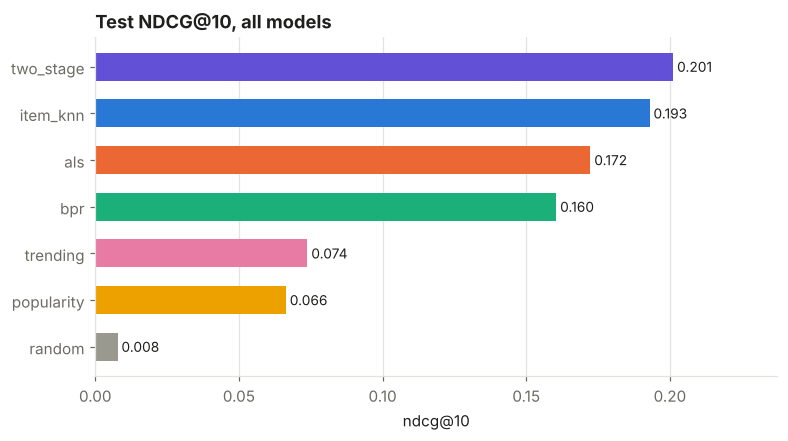

In [3]:
bar_leaderboard(board, "ndcg@10", title="Test NDCG@10, all models")
plt.show()

## 2. Is the winner *really* better? Paired bootstrap

Every model is scored on the **same users**, so compare them *paired*: resample users with replacement and recompute the **difference** in mean NDCG. If the 95% interval excludes 0, the gap is unlikely to be noise from *which users happened to be in the test week*.

In [4]:
def paired_bootstrap(a, b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    diff = a - b
    idx = rng.integers(0, len(diff), (n_boot, len(diff)))
    boots = diff[idx].mean(axis=1)
    return diff.mean(), np.percentile(boots, [2.5, 97.5])


ranked = board.index.tolist()
best = ranked[0]
rows = []
for other in ranked[1:]:
    mean, (lo, hi) = paired_bootstrap(per_user[best]["ndcg@10"].to_numpy(), per_user[other]["ndcg@10"].to_numpy())
    rows.append({"comparison": f"{best} − {other}", "Δ NDCG@10": mean, "95% CI low": lo, "95% CI high": hi,
                 "significant": lo > 0 or hi < 0})
pd.DataFrame(rows).set_index("comparison").round(4)

,Δ NDCG@10,95% CI low,95% CI high,significant
comparison,,,,
two_stage − item_knn,0.0082,-0.0040,0.0208,False
two_stage − als,0.0288,0.0158,0.0422,True
two_stage − bpr,0.0407,0.0266,0.0557,True
two_stage − trending,0.1273,0.1061,0.1491,True
two_stage − popularity,0.1348,0.1127,0.1569,True
two_stage − random,0.1934,0.1729,0.2142,True


> **Principal DS note.** With a few hundred evaluation users (synthetic data, or "cart/buy" relevance), intervals are wide and small gaps are noise. Report intervals, not just point estimates.

## 3. Who does each model serve well? Segment analysis

An average hides a lot. Split users by how much training history they have.

,popularity,item_knn,als,two_stage,users
segment,,,,,
light (2–3 items),0.0934,0.1926,0.1925,0.2019,69
medium (4–9),0.0483,0.1843,0.1705,0.2001,234
heavy (10+),0.0736,0.1992,0.1693,0.2017,324


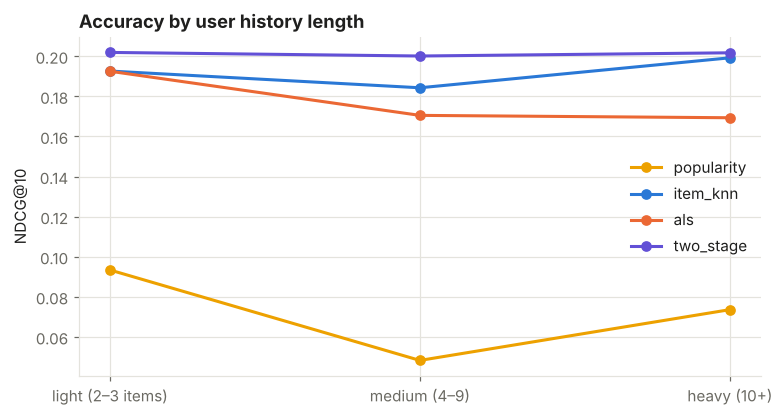

In [5]:
history = np.diff(data.X_train.indptr)
seg_bins = [0, 3, 9, np.inf]
seg_labels = ["light (2–3 items)", "medium (4–9)", "heavy (10+)"]
seg = {}
for name in ["popularity", "item_knn", "als", "two_stage"]:
    df = per_user[name].assign(segment=pd.cut(history[per_user[name]["user"]], seg_bins, labels=seg_labels))
    seg[name] = df.groupby("segment", observed=True)["ndcg@10"].mean()
seg = pd.DataFrame(seg)
seg["users"] = per_user["popularity"].assign(
    segment=pd.cut(history[per_user["popularity"]["user"]], seg_bins, labels=seg_labels)).groupby("segment", observed=True).size()
display(seg.round(4))

fig, ax = plt.subplots()
x = np.arange(len(seg_labels))
for name in ["popularity", "item_knn", "als", "two_stage"]:
    ax.plot(x, seg[name].reindex(seg_labels).values, marker="o", color=model_color(name), label=name)
ax.set_xticks(x, seg_labels); ax.set_ylabel("NDCG@10"); ax.set_title("Accuracy by user history length")
ax.legend()
plt.show()

Compare the *gap* between popularity and the personalised models across segments, not just the levels. On e-commerce data the gap is usually widest for users with richer histories, and the least-known users are where non-personalised signals compete best. That is the argument for the fallback policy in section 5, and for giving the ranker user-activity features so that it can learn *when* to trust personalisation. With few users per segment, check the bootstrap intervals before reading too much into small differences.

## 4. Popularity bias and the accuracy–diversity trade-off

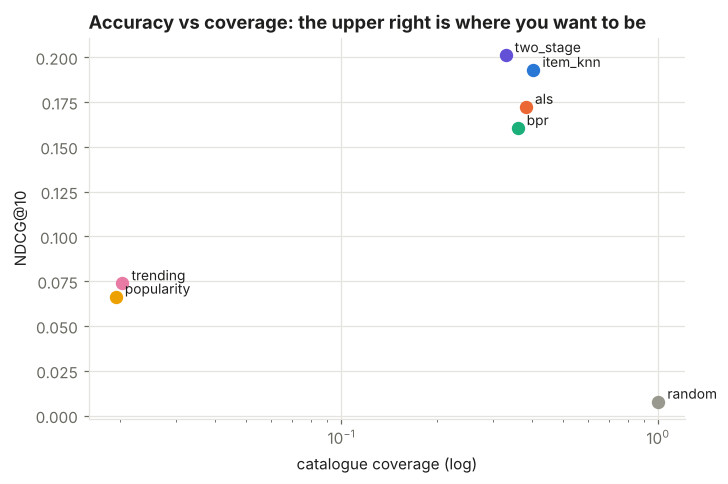

In [6]:
item_pop = np.asarray((data.X_train > 0).sum(axis=0)).ravel()
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in board.index:
    ax.scatter(board.loc[name, "coverage"], board.loc[name, "ndcg@10"], s=60, color=model_color(name), zorder=3)
    ax.annotate(name, (board.loc[name, "coverage"], board.loc[name, "ndcg@10"]), xytext=(6, 2), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("catalogue coverage (log)"); ax.set_ylabel("NDCG@10")
ax.set_title("Accuracy vs coverage: the upper right is where you want to be")
plt.show()

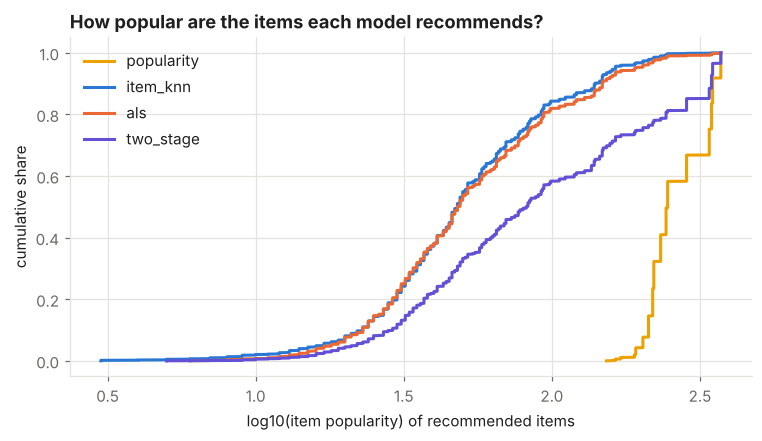

In [7]:
users = data.ground_truth.users[:2000]
fig, ax = plt.subplots()
for name in ["popularity", "item_knn", "als", "two_stage"]:
    recs = models[name].recommend(users, k=10)
    vals = np.sort(np.log10(item_pop[recs.ravel()] + 1))
    ax.plot(vals, np.linspace(0, 1, len(vals)), color=model_color(name), label=name)
ax.set_xlabel("log10(item popularity) of recommended items"); ax.set_ylabel("cumulative share")
ax.set_title("How popular are the items each model recommends?"); ax.legend()
plt.show()

Curves further left mean less popular (more long-tail) recommendations. Offline accuracy **rewards** popularity bias, because test-week behaviour is itself concentrated on popular items, which were shown more. A model tuned only for offline NDCG can quietly turn into "popularity with extra steps". Watch coverage and novelty, and test online.

## 5. A serving policy with cold start

Most visitors are unknown to the model (notebook 02). A real system needs a policy, not just a model:

In [8]:
best_model = models[best]
fallback = models["trending"]


def recommend_for_visitor(visitor_id, k=10):
    """Personalised recommendations for known visitors, and trending items otherwise."""
    u = data.user_map.to_index([visitor_id])[0]
    if u >= 0:
        items, source = best_model.recommend([u], k=k)[0], best
    else:
        items, source = fallback.item_scores_.argsort()[::-1][:k], "trending (cold start)"
    return source, data.item_map.to_raw(items)


known = data.user_map.to_raw([int(data.ground_truth.users[0])])[0]
for visitor in [known, -1]:
    src, items = recommend_for_visitor(visitor)
    print(f"visitor {visitor:>10}: {src:<22} → {[int(i) for i in items[:5]]} ...")

visitor      21328: two_stage              → [4180, 5919, 8885, 856, 13206] ...
visitor         -1: trending (cold start)  → [7427, 4477, 5446, 2599, 5675] ...


## 6. From offline to online: designing the A/B test

Offline metrics pick **candidates**. Only an online experiment tells you whether users and the business benefit. The sample size needed to detect a relative lift in click-through rate (CTR), using a two-proportion z-test:

In [9]:
from scipy.stats import norm


def users_per_arm(baseline_rate, relative_mde, alpha=0.05, power=0.8):
    p1, p2 = baseline_rate, baseline_rate * (1 + relative_mde)
    z_a, z_b = norm.ppf(1 - alpha / 2), norm.ppf(power)
    p_bar = (p1 + p2) / 2
    n = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
    return int(np.ceil(n))


pd.DataFrame([{"baseline CTR": b, "relative lift to detect": m, "users per arm": users_per_arm(b, m)}
              for b in [0.01, 0.03] for m in [0.02, 0.05, 0.10]])

,baseline CTR,relative lift to detect,users per arm
0,0.01,0.02,3923650
1,0.01,0.05,637010
2,0.01,0.10,163095
3,0.03,0.02,1281194
4,0.03,0.05,207938
5,0.03,0.10,53211


**Experiment design checklist**

* **Primary metric**: carousel add-to-cart rate per user (closer to revenue than CTR).
* **Guardrails**: overall conversion rate, revenue per visitor, page latency, catalogue coverage, and the share of recommendations that are out of stock.
* **Randomise by user**, not by page view, so that each user has a consistent experience.
* **Pre-register** the duration (whole weeks, to cover weekly cycles) and the analysis. Don't peek and stop early.
* **Novelty effects**: new widgets get clicked because they are new. Look at the trend over time, not just the total.

## 7. Production architecture (batch, daily)

```
 event stream ──▶ data lake ──▶ nightly job ─┬─▶ train / refresh generators (kNN, ALS)
                                             ├─▶ build features, apply ranker
                                             └─▶ write top-50 per known user ──▶ key-value store (user → items)
                                                                                    │
 web request ──▶ recommendation API ──▶ look up user ──found──▶ filter (stock, already bought) ──▶ top-10
                                           └──not found──▶ trending list (refreshed hourly)
```

**What to monitor**

| Kind | Examples |
|---|---|
| Data | event volume, share of bots, share of unknown items, schema changes |
| Model | offline NDCG on a rolling window, candidate recall, coverage, score distribution drift |
| Product | CTR, add-to-cart rate, revenue per session, latency, empty-result rate |

**Feedback loops.** Users can only click what you show them. Tomorrow's training data is shaped by today's model, which reinforces popularity. Mitigations: keep a small **exploration** slice (for example, 5% of slots get randomised candidates), log **impressions** as well as clicks, and consider inverse-propensity weighting in evaluation.

## 8. What I would do next (Principal DS backlog)

1. **Log impressions.** Without them we cannot tell "not interested" from "never saw it". This is the single biggest data improvement.
2. **Session-aware models** (co-visitation, GRU4Rec/SASRec) for the many short-history visitors.
3. **Content features** (category, price, availability) in the ranker and for cold-start items.
4. **Business rules in the ranker**: in-stock, margin, de-duplicating near-identical items, diversity.
5. **Rolling-origin evaluation** across several weeks, to make model selection robust to one odd week.

## Key takeaways

* A leaderboard is the start of evaluation, not the end. Look at segments, intervals and bias.
* The serving **policy** (cold-start fallback, filters) matters as much as the model.
* Offline wins earn an A/B test. Online results decide what ships.

## Exercises

1. **(Easy)** Re-run the leaderboard with `prepare_data(events, target_events=("addtocart", "transaction"))`. Does the winner change? How wide are the bootstrap intervals now?
2. **(Medium)** Implement **intra-list diversity**: the mean pairwise (1 − cosine) of ALS item embeddings within each list. Plot it against NDCG for every model.
3. **(Medium)** Re-rank the two-stage output with **MMR** (maximal marginal relevance) to trade a little accuracy for diversity. Chart the trade-off curve.
4. **(Stretch)** Simulate a feedback loop. Retrain popularity on a log where users can only interact with what the previous model recommended, for 5 rounds, and plot coverage over rounds.